In [ ]:

# SALON EXPERIMENT & CAUSAL ANALYSIS
# Step 1: Generate simulated salon business data

import pandas as pd
import numpy as np

np.random.seed(42)

# Generate 300,000 appointment records
n = 300000

data = pd.DataFrame({
    "appointment_id": range(1, n + 1),
    "outlet_id": np.random.randint(1, 23, n),
    "client_id": np.random.randint(1000, 25000, n),
    "service": np.random.choice(
        ["Haircut", "Facial", "Hair Spa", "Manicure", "Pedicure"],
        n
    ),
    "stylist_id": np.random.randint(1, 101, n),
    "appointment_date": pd.date_range(
        start="2025-01-01", periods=n, freq="min"
    ),
    "treatment_group": np.random.choice(
        ["Control", "Treatment"], n
    ),
    "revenue": np.random.normal(1200, 300, n).clip(100, 5000),
    "no_show": np.random.choice([0, 1], n, p=[0.88, 0.12]),
    "retained": np.random.choice([0, 1], n, p=[0.30, 0.70])
})

# Add some realistic missing client IDs for walk-ins
walkin_indices = np.random.choice(
    data.index, size=5000, replace=False
)
data.loc[walkin_indices, "client_id"] = np.nan

# Save dataset
data.to_csv("salon_experiment_data.csv", index=False)

print("Dataset created successfully!")
print("Shape:", data.shape)
print(data.head())


Dataset created successfully!
Shape: (300000, 10)
   appointment_id  outlet_id  client_id   service  stylist_id  \
0               1          7     1414.0    Facial          91   
1               2         20    16301.0   Haircut          80   
2               3         15     4041.0  Hair Spa          68   
3               4         11    10830.0  Pedicure           3   
4               5          8    23529.0    Facial          43   

     appointment_date treatment_group      revenue  no_show  retained  
0 2025-01-01 00:00:00       Treatment  1255.953073        1         1  
1 2025-01-01 00:01:00         Control  1427.964122        0         0  
2 2025-01-01 00:02:00         Control  1050.224356        0         1  
3 2025-01-01 00:03:00       Treatment  1408.000792        0         1  
4 2025-01-01 00:04:00       Treatment   799.647188        0         1  


In [ ]:

# STEP 2: DATA UNDERSTANDING

import pandas as pd
import numpy as np

# Load dataset
df = pd.read_csv("salon_experiment_data.csv")

# 1. Dataset dimensions
print("Dataset Shape:", df.shape)

# 2. Column information
print("\nColumn Names:")
print(df.columns.tolist())

# 3. First five records
print("\nFirst 5 Records:")
display(df.head())

# 4. Dataset information
print("\nDataset Information:")
df.info()

# 5. Missing values
print("\nMissing Values:")
print(df.isnull().sum())

# 6. Duplicate records
print("\nDuplicate Records:", df.duplicated().sum())

# 7. Statistical summary
print("\nStatistical Summary:")
display(df.describe())

# 8. Treatment group distribution
print("\nTreatment Group Distribution:")
print(df["treatment_group"].value_counts())


Dataset Shape: (300000, 10)

Column Names:
['appointment_id', 'outlet_id', 'client_id', 'service', 'stylist_id', 'appointment_date', 'treatment_group', 'revenue', 'no_show', 'retained']

First 5 Records:


,appointment_id,outlet_id,client_id,service,stylist_id,appointment_date,treatment_group,revenue,no_show,retained
0,1,7,1414.0,Facial,91,2025-01-01 00:00:00,Treatment,1255.953073,1,1
1,2,20,16301.0,Haircut,80,2025-01-01 00:01:00,Control,1427.964122,0,0
2,3,15,4041.0,Hair Spa,68,2025-01-01 00:02:00,Control,1050.224356,0,1
3,4,11,10830.0,Pedicure,3,2025-01-01 00:03:00,Treatment,1408.000792,0,1
4,5,8,23529.0,Facial,43,2025-01-01 00:04:00,Treatment,799.647188,0,1



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300000 entries, 0 to 299999
Data columns (total 10 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   appointment_id    300000 non-null  int64  
 1   outlet_id         300000 non-null  int64  
 2   client_id         295000 non-null  float64
 3   service           300000 non-null  object 
 4   stylist_id        300000 non-null  int64  
 5   appointment_date  300000 non-null  object 
 6   treatment_group   300000 non-null  object 
 7   revenue           300000 non-null  float64
 8   no_show           300000 non-null  int64  
 9   retained          300000 non-null  int64  
dtypes: float64(2), int64(5), object(3)
memory usage: 22.9+ MB

Missing Values:
appointment_id         0
outlet_id              0
client_id           5000
service                0
stylist_id             0
appointment_date       0
treatment_group        0
revenue                0
no_show    

,appointment_id,outlet_id,client_id,stylist_id,revenue,no_show,retained
count,300000.000000,300000.000000,295000.000000,300000.000000,300000.000000,300000.000000,300000.000000
mean,150000.500000,11.500963,12997.392532,50.582127,1199.013169,0.119237,0.699597
std,86602.684716,6.344467,6925.768795,28.867837,300.230814,0.324067,0.458434
min,1.000000,1.000000,1000.000000,1.000000,100.000000,0.000000,0.000000
25%,75000.750000,6.000000,7004.000000,26.000000,996.455763,0.000000,0.000000
50%,150000.500000,12.000000,12998.000000,51.000000,1199.176213,0.000000,1.000000
75%,225000.250000,17.000000,18984.000000,76.000000,1401.431503,0.000000,1.000000
max,300000.000000,22.000000,24999.000000,100.000000,2584.915177,1.000000,1.000000



Treatment Group Distribution:
treatment_group
Treatment    150101
Control      149899
Name: count, dtype: int64


In [ ]:

# STEP 3: DATA CLEANING

# Work on a copy
clean_df = df.copy()

# 1. Check missing values
print("Missing values before cleaning:")
print(clean_df.isnull().sum())

# 2. Identify walk-in customers
clean_df["customer_type"] = np.where(
    clean_df["client_id"].isna(),
    "Walk-in",
    "Registered"
)

# 3. Standardise service names
clean_df["service"] = clean_df["service"].str.strip().str.title()

# 4. Convert appointment date
clean_df["appointment_date"] = pd.to_datetime(
    clean_df["appointment_date"]
)

# 5. Handle missing client IDs
# Keep them missing because these are walk-in customers.
# Do not invent customer identities.

# 6. Check invalid revenue
clean_df = clean_df[
    clean_df["revenue"].notna() &
    (clean_df["revenue"] >= 0)
]

# 7. Remove duplicate appointment IDs
clean_df = clean_df.drop_duplicates(
    subset=["appointment_id"]
)

# 8. Verify cleaned dataset
print("\nCleaning completed!")

print("Final shape:", clean_df.shape)

print("\nCustomer types:")
print(clean_df["customer_type"].value_counts())

print("\nMissing values after cleaning:")
print(clean_df.isnull().sum())

print("\nDuplicate appointment IDs:",
      clean_df["appointment_id"].duplicated().sum())


Missing values before cleaning:
appointment_id         0
outlet_id              0
client_id           5000
service                0
stylist_id             0
appointment_date       0
treatment_group        0
revenue                0
no_show                0
retained               0
dtype: int64

Cleaning completed!
Final shape: (300000, 11)

Customer types:
customer_type
Registered    295000
Walk-in         5000
Name: count, dtype: int64

Missing values after cleaning:
appointment_id         0
outlet_id              0
client_id           5000
service                0
stylist_id             0
appointment_date       0
treatment_group        0
revenue                0
no_show                0
retained               0
customer_type          0
dtype: int64

Duplicate appointment IDs: 0


In [ ]:

!pip install seaborn -q

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")


Libraries imported successfully!


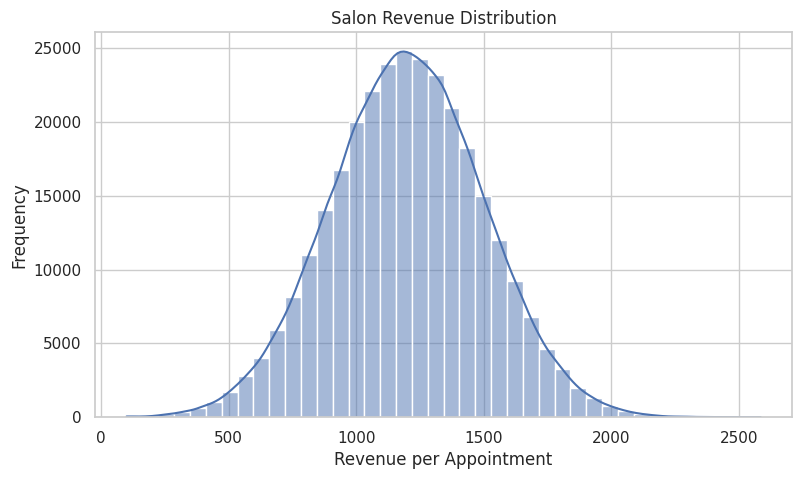

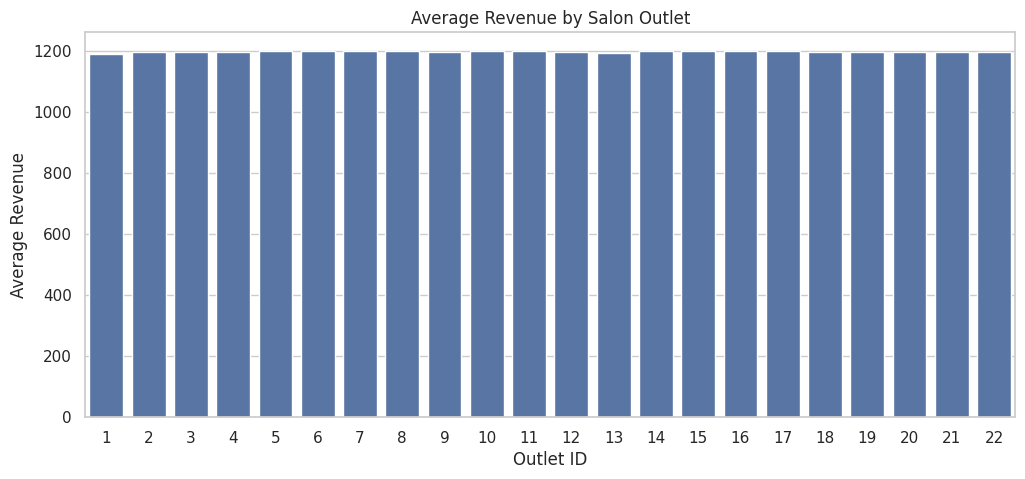

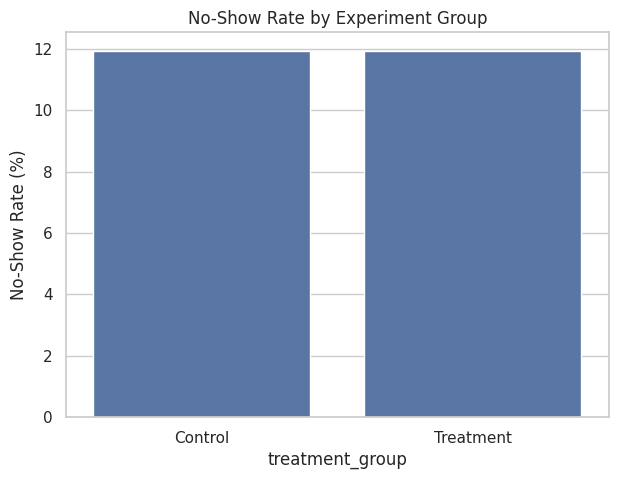

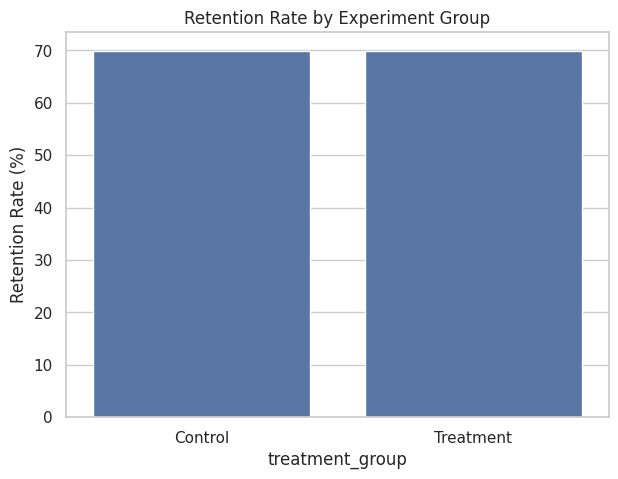

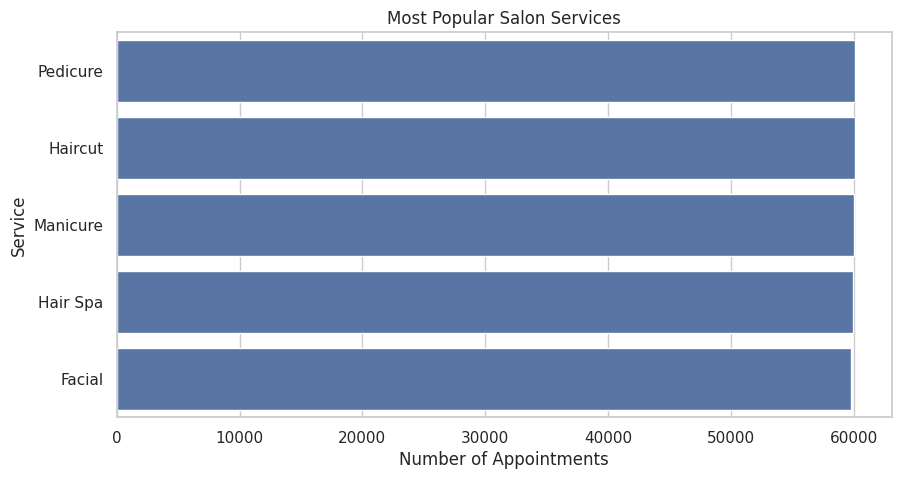

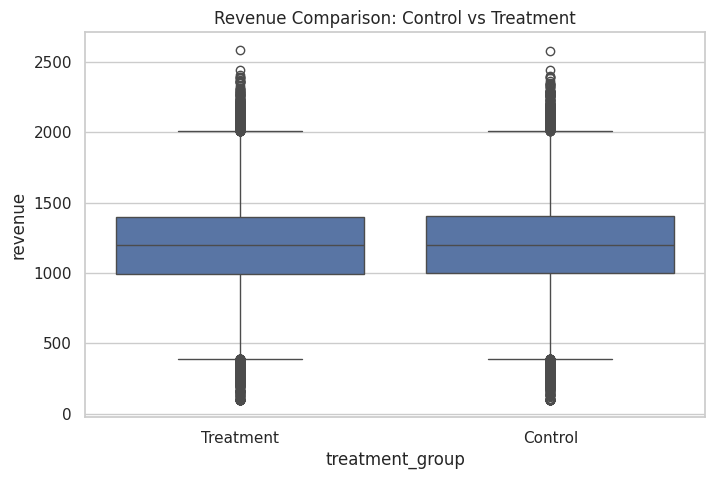

EDA completed successfully!


In [ ]:

# STEP 4: EXPLORATORY DATA ANALYSIS

# 1. Revenue distribution
plt.figure(figsize=(9, 5))
sns.histplot(clean_df["revenue"], bins=40, kde=True)
plt.title("Salon Revenue Distribution")
plt.xlabel("Revenue per Appointment")
plt.ylabel("Frequency")
plt.show()


# 2. Revenue by outlet
outlet_revenue = clean_df.groupby(
    "outlet_id"
)["revenue"].mean().reset_index()

plt.figure(figsize=(12, 5))
sns.barplot(
    data=outlet_revenue,
    x="outlet_id",
    y="revenue"
)
plt.title("Average Revenue by Salon Outlet")
plt.xlabel("Outlet ID")
plt.ylabel("Average Revenue")
plt.show()


# 3. No-show rate by treatment group
noshow_analysis = clean_df.groupby(
    "treatment_group"
)["no_show"].mean().reset_index()

noshow_analysis["no_show"] *= 100

plt.figure(figsize=(7, 5))
sns.barplot(
    data=noshow_analysis,
    x="treatment_group",
    y="no_show"
)
plt.title("No-Show Rate by Experiment Group")
plt.ylabel("No-Show Rate (%)")
plt.show()


# 4. Retention rate by treatment group
retention_analysis = clean_df.groupby(
    "treatment_group"
)["retained"].mean().reset_index()

retention_analysis["retained"] *= 100

plt.figure(figsize=(7, 5))
sns.barplot(
    data=retention_analysis,
    x="treatment_group",
    y="retained"
)
plt.title("Retention Rate by Experiment Group")
plt.ylabel("Retention Rate (%)")
plt.show()


# 5. Service popularity
plt.figure(figsize=(10, 5))
sns.countplot(
    data=clean_df,
    y="service",
    order=clean_df["service"].value_counts().index
)
plt.title("Most Popular Salon Services")
plt.xlabel("Number of Appointments")
plt.ylabel("Service")
plt.show()


# 6. Revenue by experiment group
plt.figure(figsize=(8, 5))
sns.boxplot(
    data=clean_df,
    x="treatment_group",
    y="revenue"
)
plt.title("Revenue Comparison: Control vs Treatment")
plt.show()

print("EDA completed successfully!")


In [ ]:

# STEP 5: POWER ANALYSIS

!pip install statsmodels -q

from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize
import math

# Experiment assumptions
baseline_retention = 0.30
expected_retention = 0.33

alpha = 0.05
power = 0.80

# Calculate effect size
effect_size = proportion_effectsize(
    expected_retention,
    baseline_retention
)

# Calculate sample size
analysis = NormalIndPower()

sample_per_group = analysis.solve_power(
    effect_size=effect_size,
    power=power,
    alpha=alpha,
    ratio=1,
    alternative="two-sided"
)

sample_per_group = math.ceil(sample_per_group)

# Add 10% allowance for attrition
adjusted_sample = math.ceil(sample_per_group / 0.90)

total_sample = adjusted_sample * 2

print("POWER ANALYSIS RESULTS")
print("----------------------")
print("Baseline retention:", baseline_retention * 100, "%")
print("Expected retention:", expected_retention * 100, "%")
print("Significance level:", alpha)
print("Statistical power:", power * 100, "%")
print("Required sample per group:", sample_per_group)
print("Adjusted sample per group:", adjusted_sample)
print("Total required participants:", total_sample)


POWER ANALYSIS RESULTS
----------------------
Baseline retention: 30.0 %
Expected retention: 33.0 %
Significance level: 0.05
Statistical power: 80.0 %
Required sample per group: 3762
Adjusted sample per group: 4180
Total required participants: 8360


In [ ]:

# STEP 6.1: CREATE EXPERIMENT DATASET

import pandas as pd
import numpy as np

from scipy.stats import chisquare, chi2_contingency, ttest_ind

np.random.seed(42)

n = 20000

# Create customer records
experiment_df = pd.DataFrame({
    "customer_id": range(100001, 100001 + n),
    "outlet_id": np.random.randint(1, 23, n),
    "baseline_monthly_visits": np.random.poisson(2, n) + 1,
    "baseline_revenue": np.random.normal(1200, 250, n).clip(300, 3000),
    "baseline_retention": np.random.binomial(1, 0.30, n)
})

# Randomly assign customers within each outlet
experiment_df["treatment_group"] = ""

for outlet in experiment_df["outlet_id"].unique():
    idx = experiment_df.index[
        experiment_df["outlet_id"] == outlet
    ]

    experiment_df.loc[idx, "treatment_group"] = np.random.choice(
        ["Control", "Treatment"],
        size=len(idx),
        p=[0.5, 0.5]
    )

# Generate simulated experiment outcomes
treatment = (
    experiment_df["treatment_group"] == "Treatment"
).astype(int)

# 30-day customer retention
retention_probability = (
    0.30 + 0.03 * treatment
)

experiment_df["retained_30d"] = np.random.binomial(
    1, retention_probability
)

# No-show outcome
noshow_probability = (
    0.12 - 0.02 * treatment
)

experiment_df["no_show"] = np.random.binomial(
    1, noshow_probability
)

# Revenue per completed visit
experiment_df["revenue_per_visit"] = (
    np.random.normal(1200, 250, n) + 50 * treatment
).clip(300, 3500)

# Save experiment dataset
experiment_df.to_csv(
    "salon_ab_experiment.csv",
    index=False
)

print("Experiment dataset created!")
print("Shape:", experiment_df.shape)
display(experiment_df.head())


Experiment dataset created!
Shape: (20000, 9)


,customer_id,outlet_id,baseline_monthly_visits,baseline_revenue,baseline_retention,treatment_group,retained_30d,no_show,revenue_per_visit
0,100001,7,4,631.225669,1,Treatment,1,0,1080.358053
1,100002,20,4,1077.703920,1,Control,1,0,1349.480607
2,100003,15,2,954.266152,0,Treatment,0,0,1652.016079
3,100004,11,4,1090.725263,1,Control,0,0,1443.302320
4,100005,8,5,1654.881052,0,Control,0,0,716.048852


In [ ]:

# STEP 6.2: SAMPLE RATIO MISMATCH

group_counts = experiment_df["treatment_group"].value_counts()

observed = [
    group_counts.get("Control", 0),
    group_counts.get("Treatment", 0)
]

expected = [
    len(experiment_df) / 2,
    len(experiment_df) / 2
]

chi_stat, p_value = chisquare(
    f_obs=observed,
    f_exp=expected
)

print("CONTROL:", observed[0])
print("TREATMENT:", observed[1])
print("Chi-square statistic:", chi_stat)
print("SRM p-value:", p_value)

if p_value < 0.001:
    print("WARNING: Possible Sample Ratio Mismatch!")
else:
    print("No significant SRM detected.")


CONTROL: 10000
TREATMENT: 10000
Chi-square statistic: 0.0
SRM p-value: 1.0
No significant SRM detected.


In [ ]:

# STEP 6.3: RANDOMISATION BALANCE

baseline_columns = [
    "baseline_monthly_visits",
    "baseline_revenue",
    "baseline_retention"
]

for column in baseline_columns:

    control = experiment_df.loc[
        experiment_df["treatment_group"] == "Control",
        column
    ]

    treatment = experiment_df.loc[
        experiment_df["treatment_group"] == "Treatment",
        column
    ]

    t_stat, p_value = ttest_ind(
        control,
        treatment,
        equal_var=False
    )

    print("\nVariable:", column)
    print("Control Mean:", round(control.mean(), 3))
    print("Treatment Mean:", round(treatment.mean(), 3))
    print("P-value:", round(p_value, 4))

    if p_value < 0.05:
        print("Potential baseline imbalance")
    else:
        print("No statistically significant difference")



Variable: baseline_monthly_visits
Control Mean: 3.03
Treatment Mean: 2.983
P-value: 0.0188
Potential baseline imbalance

Variable: baseline_revenue
Control Mean: 1201.718
Treatment Mean: 1201.079
P-value: 0.8566
No statistically significant difference

Variable: baseline_retention
Control Mean: 0.303
Treatment Mean: 0.302
P-value: 0.9877
No statistically significant difference


treatment_group  Control  Treatment
outlet_id                          
1                    422        468
2                    438        460
3                    466        422
4                    457        443
5                    429        455
6                    433        448
7                    454        434
8                    467        441
9                    455        426
10                   449        455
11                   417        401
12                   458        446
13                   468        504
14                   415        449
15                   505        477
16                   464        475
17                   484        490
18                   445        472
19                   484        451
20                   465        433
21                   447        471
22                   478        479


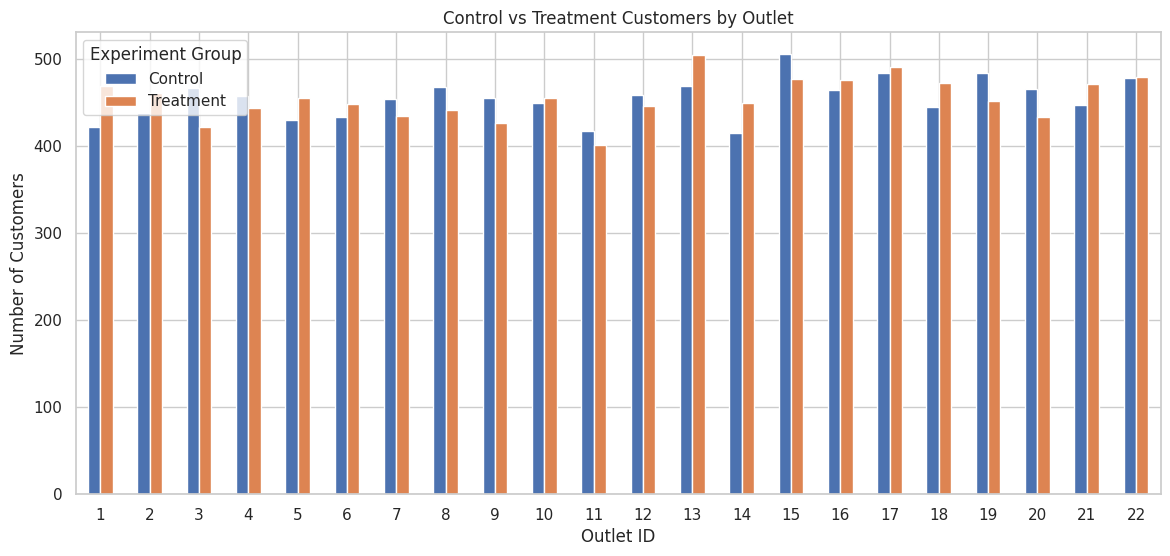

In [ ]:

# STEP 6.4: OUTLET-LEVEL GROUP DISTRIBUTION

outlet_balance = pd.crosstab(
    experiment_df["outlet_id"],
    experiment_df["treatment_group"]
)

print(outlet_balance)

outlet_balance.plot(
    kind="bar",
    figsize=(14, 6)
)

plt.title("Control vs Treatment Customers by Outlet")
plt.xlabel("Outlet ID")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.legend(title="Experiment Group")
plt.show()


In [ ]:

# STEP 7.1: TREATMENT EFFECT ANALYSIS

from scipy.stats import ttest_ind
import numpy as np
import pandas as pd

metrics = [
    "retained_30d",
    "revenue_per_visit",
    "no_show"
]

results = []

for metric in metrics:

    control = experiment_df.loc[
        experiment_df["treatment_group"] == "Control",
        metric
    ].dropna()

    treatment = experiment_df.loc[
        experiment_df["treatment_group"] == "Treatment",
        metric
    ].dropna()

    # Difference in means
    effect = treatment.mean() - control.mean()

    # Welch's independent t-test
    t_stat, p_value = ttest_ind(
        treatment,
        control,
        equal_var=False
    )

    results.append({
        "Metric": metric,
        "Control Mean": control.mean(),
        "Treatment Mean": treatment.mean(),
        "Treatment Effect": effect,
        "P-value": p_value
    })

effect_results = pd.DataFrame(results)

display(effect_results.round(4))


,Metric,Control Mean,Treatment Mean,Treatment Effect,P-value
0,retained_30d,0.3065,0.3403,0.0338,0.0
1,revenue_per_visit,1199.7344,1248.8158,49.0814,0.0
2,no_show,0.1218,0.1001,-0.0217,0.0


In [ ]:

# STEP 7.3: BOOTSTRAP CONFIDENCE INTERVALS

def bootstrap_ci(control, treatment, iterations=2000):

    control = np.asarray(control)
    treatment = np.asarray(treatment)

    differences = []

    for _ in range(iterations):

        control_sample = np.random.choice(
            control,
            size=len(control),
            replace=True
        )

        treatment_sample = np.random.choice(
            treatment,
            size=len(treatment),
            replace=True
        )

        differences.append(
            treatment_sample.mean() -
            control_sample.mean()
        )

    lower = np.percentile(differences, 2.5)
    upper = np.percentile(differences, 97.5)

    return lower, upper


bootstrap_results = []

for metric in metrics:

    control = experiment_df.loc[
        experiment_df["treatment_group"] == "Control",
        metric
    ].dropna()

    treatment = experiment_df.loc[
        experiment_df["treatment_group"] == "Treatment",
        metric
    ].dropna()

    lower, upper = bootstrap_ci(
        control,
        treatment
    )

    bootstrap_results.append({
        "Metric": metric,
        "Effect": treatment.mean() - control.mean(),
        "95% CI Lower": lower,
        "95% CI Upper": upper
    })

bootstrap_df = pd.DataFrame(bootstrap_results)

print("BOOTSTRAP RESULTS")
display(bootstrap_df.round(4))


BOOTSTRAP RESULTS


,Metric,Effect,95% CI Lower,95% CI Upper
0,retained_30d,0.0338,0.0204,0.0463
1,revenue_per_visit,49.0814,42.0637,56.0908
2,no_show,-0.0217,-0.0302,-0.0131


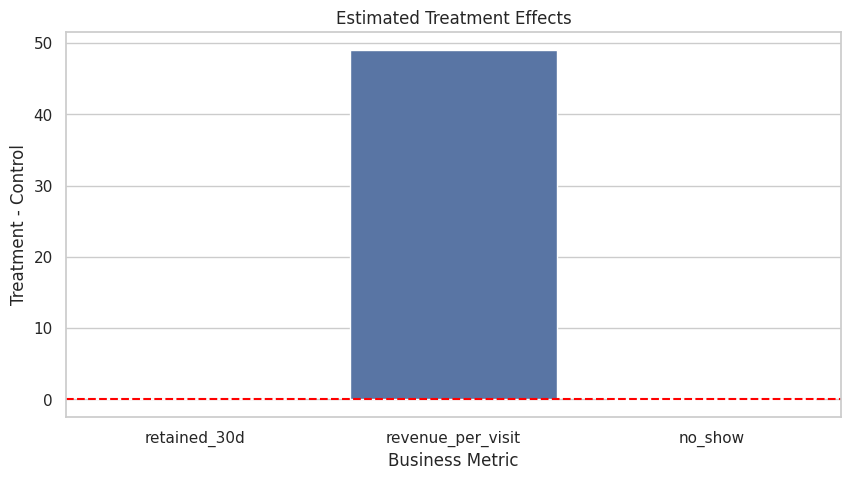

In [ ]:

# STEP 7.4: TREATMENT EFFECT VISUALISATION

plt.figure(figsize=(10, 5))

sns.barplot(
    data=effect_results,
    x="Metric",
    y="Treatment Effect"
)

plt.axhline(0, linestyle="--", color="red")
plt.title("Estimated Treatment Effects")
plt.xlabel("Business Metric")
plt.ylabel("Treatment - Control")
plt.show()


In [ ]:

# STEP 8.2: SIMULATE HISTORICAL DATA FOR DID

import pandas as pd
import numpy as np

np.random.seed(42)

records = []

outlets = range(1, 23)
weeks = range(-12, 13)

for outlet in outlets:

    # First 11 outlets are treatment outlets
    treated = 1 if outlet <= 11 else 0

    # Outlet-specific baseline
    outlet_effect = np.random.normal(0, 50)

    for week in weeks:

        post = 1 if week >= 1 else 0

        # Common time trend
        time_effect = week * 3

        # Simulated intervention effect
        intervention_effect = (
            50 * treated * post
        )

        revenue = (
            1200
            + outlet_effect
            + time_effect
            + intervention_effect
            + np.random.normal(0, 25)
        )

        records.append({
            "outlet_id": outlet,
            "week": week,
            "treated": treated,
            "post": post,
            "revenue_per_visit": revenue
        })

did_df = pd.DataFrame(records)

print("Historical dataset created!")
print("Shape:", did_df.shape)

display(did_df.head())


Historical dataset created!
Shape: (550, 5)


,outlet_id,week,treated,post,revenue_per_visit
0,1,-12,1,0,1185.379100
1,1,-11,1,0,1208.027921
2,1,-10,1,0,1232.911454
3,1,-9,1,0,1191.981873
4,1,-8,1,0,1194.982284


In [ ]:

# STEP 8.3: MANUAL DID CALCULATION

did_summary = did_df.groupby(
    ["treated", "post"]
)["revenue_per_visit"].mean().unstack()

print("Average Revenue per Visit")
display(did_summary)

treatment_change = (
    did_summary.loc[1, 1] -
    did_summary.loc[1, 0]
)

control_change = (
    did_summary.loc[0, 1] -
    did_summary.loc[0, 0]
)

did_effect = treatment_change - control_change

print("Treatment Group Change:", treatment_change)
print("Control Group Change:", control_change)
print("Difference-in-Differences Effect:", did_effect)


Average Revenue per Visit


post,0,1
treated,,
0,1183.325482,1219.472154
1,1180.321102,1266.691935


Treatment Group Change: 86.37083213802953
Control Group Change: 36.14667239097503
Difference-in-Differences Effect: 50.2241597470545


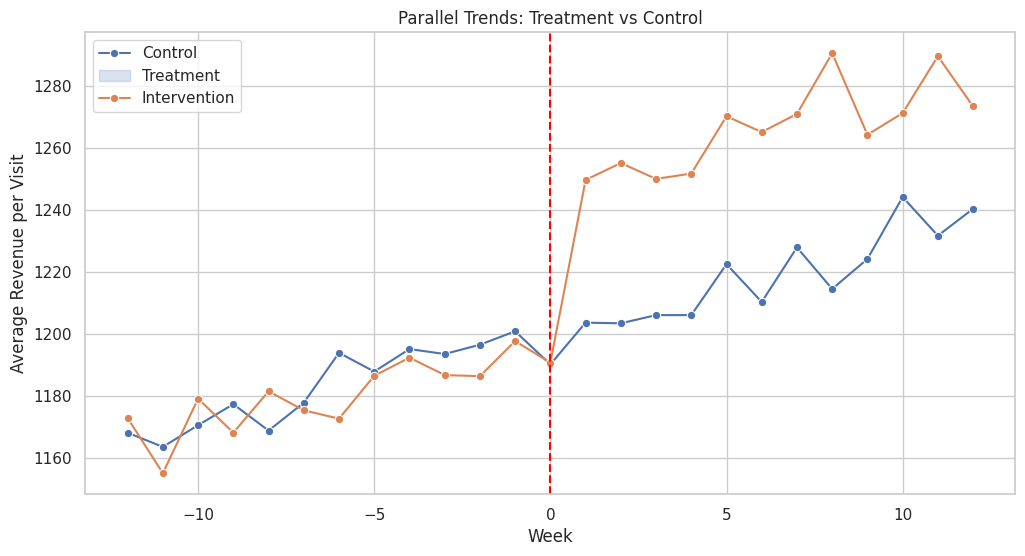

In [ ]:

# STEP 8.4: PARALLEL TRENDS GRAPH

trend_data = did_df.groupby(
    ["week", "treated"]
)["revenue_per_visit"].mean().reset_index()

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=trend_data,
    x="week",
    y="revenue_per_visit",
    hue="treated",
    marker="o"
)

plt.axvline(
    x=0,
    color="red",
    linestyle="--",
    label="Intervention boundary"
)

plt.title("Parallel Trends: Treatment vs Control")
plt.xlabel("Week")
plt.ylabel("Average Revenue per Visit")
plt.legend(
    labels=["Control", "Treatment", "Intervention"]
)
plt.show()


In [ ]:

# STEP 8.5: DID REGRESSION

import statsmodels.formula.api as smf

did_df["interaction"] = (
    did_df["treated"] * did_df["post"]
)

model = smf.ols(
    "revenue_per_visit ~ treated + post + interaction + C(outlet_id) + C(week)",
    data=did_df
).fit(
    cov_type="cluster",
    cov_kwds={"groups": did_df["outlet_id"]}
)

print(model.summary())

effect = model.params["interaction"]
ci = model.conf_int().loc["interaction"]

print("\nDID EFFECT:", round(effect, 2))
print("95% Confidence Interval:")
print(ci)
print("P-value:", model.pvalues["interaction"])


                            OLS Regression Results                            
Dep. Variable:      revenue_per_visit   R-squared:                       0.901
Model:                            OLS   Adj. R-squared:                  0.892
Method:                 Least Squares   F-statistic:                     14.53
Date:                Thu, 12 Nov 2026   Prob (F-statistic):           3.16e-08
Time:                        13:26:38   Log-Likelihood:                -2512.8
No. Observations:                 550   AIC:                             5120.
Df Residuals:                     503   BIC:                             5322.
Df Model:                          46                                         
Covariance Type:              cluster                                         
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept           1083.2829      4

/tmp/ipykernel_8739/2217846690.py:12: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  ).fit(
/usr/local/lib/python3.13/dist-packages/statsmodels/base/model.py:1988: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 48, but rank is 21
  res = self.wald_test(


In [ ]:

# STEP 8.6: PRE-TREATMENT TREND TEST

pre_df = did_df[did_df["week"] < 0].copy()

trend_model = smf.ols(
    "revenue_per_visit ~ treated * week + C(outlet_id)",
    data=pre_df
).fit(
    cov_type="cluster",
    cov_kwds={"groups": pre_df["outlet_id"]}
)

print(trend_model.summary())

trend_p = trend_model.pvalues["treated:week"]

print("\nPre-trend interaction p-value:", trend_p)

if trend_p < 0.05:
    print("Warning: Evidence of different pre-treatment trends.")
else:
    print("No statistically significant difference in linear pre-trends.")


                            OLS Regression Results                            
Dep. Variable:      revenue_per_visit   R-squared:                       0.881
Model:                            OLS   Adj. R-squared:                  0.870
Method:                 Least Squares   F-statistic:                 4.339e+04
Date:                Thu, 12 Nov 2026   Prob (F-statistic):           1.07e-38
Time:                        13:26:38   Log-Likelihood:                -1203.7
No. Observations:                 264   AIC:                             2455.
Df Residuals:                     240   BIC:                             2541.
Df Model:                          23                                         
Covariance Type:              cluster                                         
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept           1114.1621      3

/tmp/ipykernel_8739/2736711101.py:8: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  ).fit(
/usr/local/lib/python3.13/dist-packages/statsmodels/base/model.py:1988: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 24, but rank is 2
  res = self.wald_test(


,customer_segment,treatment_group,retained_30d,retention_percentage
0,Frequent Customers,Control,0.307220,30.721992
1,Frequent Customers,Treatment,0.339437,33.943710
2,Occasional Customers,Control,0.305409,30.540881
3,Occasional Customers,Treatment,0.341541,34.154071


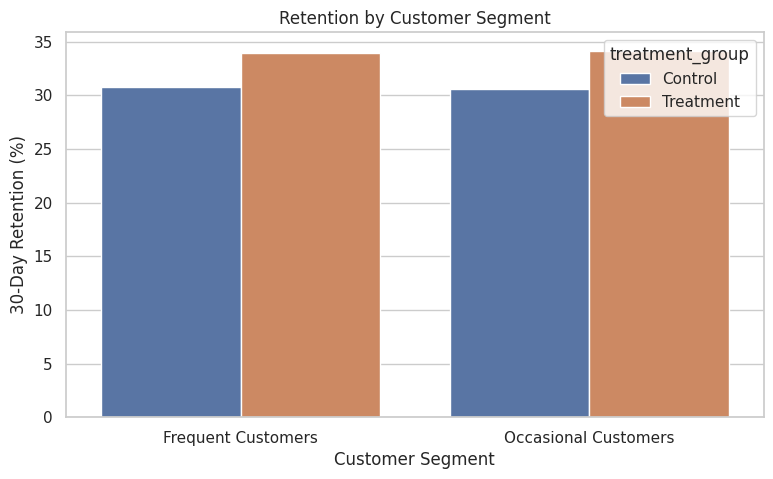

In [ ]:

# STEP 9.1: CUSTOMER SEGMENTATION

# Divide customers based on previous visit frequency
experiment_df["customer_segment"] = np.where(
    experiment_df["baseline_monthly_visits"] >= 3,
    "Frequent Customers",
    "Occasional Customers"
)

# Compare retention by customer segment
segment_results = experiment_df.groupby(
    ["customer_segment", "treatment_group"]
)["retained_30d"].mean().reset_index()

segment_results["retention_percentage"] = (
    segment_results["retained_30d"] * 100
)

display(segment_results)

# Visualisation
plt.figure(figsize=(9, 5))

sns.barplot(
    data=segment_results,
    x="customer_segment",
    y="retention_percentage",
    hue="treatment_group"
)

plt.title("Retention by Customer Segment")
plt.ylabel("30-Day Retention (%)")
plt.xlabel("Customer Segment")
plt.show()


In [ ]:

print("Available columns:")
print(experiment_df.columns.tolist())

print("\nDataset shape:")
print(experiment_df.shape)


Available columns:
['customer_id', 'outlet_id', 'baseline_monthly_visits', 'baseline_revenue', 'baseline_retention', 'treatment_group', 'retained_30d', 'no_show', 'revenue_per_visit', 'customer_segment']

Dataset shape:
(20000, 10)


In [ ]:

# STEP 9.3 - CUPED KEYERROR FIX

import numpy as np
import pandas as pd
from scipy.stats import ttest_ind

# Check dataset
print("Available columns:", experiment_df.columns.tolist())

# Required columns
required_columns = [
    "treatment_group",
    "retained_30d",
    "baseline_monthly_visits"
]

# Check missing columns
missing = [
    col for col in required_columns
    if col not in experiment_df.columns
]

if missing:
    print("Missing columns:", missing)
    print("Please rerun Step 6.1 to generate the correct dataset.")

else:
    cuped_df = experiment_df[required_columns].copy()

    # Separate groups
    control = cuped_df[
        cuped_df["treatment_group"] == "Control"
    ]

    treatment = cuped_df[
        cuped_df["treatment_group"] == "Treatment"
    ]

    # Calculate CUPED
    X = cuped_df["baseline_monthly_visits"].astype(float)
    Y = cuped_df["retained_30d"].astype(float)

    theta = np.cov(X, Y, ddof=1)[0, 1] / X.var(ddof=1)

    cuped_df["retention_cuped"] = (
        Y - theta * (X - X.mean())
    )

    # Updated groups
    control = cuped_df[
        cuped_df["treatment_group"] == "Control"
    ]

    treatment = cuped_df[
        cuped_df["treatment_group"] == "Treatment"
    ]

    original_effect = (
        treatment["retained_30d"].mean()
        - control["retained_30d"].mean()
    )

    cuped_effect = (
        treatment["retention_cuped"].mean()
        - control["retention_cuped"].mean()
    )

    original_test = ttest_ind(
        treatment["retained_30d"],
        control["retained_30d"],
        equal_var=False
    )

    cuped_test = ttest_ind(
        treatment["retention_cuped"],
        control["retention_cuped"],
        equal_var=False
    )

    print("\n===== CUPED RESULTS =====")
    print("Original effect:", original_effect)
    print("CUPED effect:", cuped_effect)
    print("Original p-value:", original_test.pvalue)
    print("CUPED p-value:", cuped_test.pvalue)

    print("\nCUPED ANALYSIS COMPLETED!")


Available columns: ['customer_id', 'outlet_id', 'baseline_monthly_visits', 'baseline_revenue', 'baseline_retention', 'treatment_group', 'retained_30d', 'no_show', 'revenue_per_visit', 'customer_segment']

===== CUPED RESULTS =====
Original effect: 0.0338
CUPED effect: 0.033832791000374784
Original p-value: 3.2097030771966275e-07
CUPED p-value: 3.126275744820322e-07

CUPED ANALYSIS COMPLETED!


In [ ]:

# STEP 9.4 - ESTIMATE SAMPLE SIZE AND TEST DURATION

import numpy as np
from scipy.stats import norm

# Experiment settings
alpha = 0.05
power = 0.80
baseline_retention = 0.30
expected_retention = 0.33
mde = expected_retention - baseline_retention

# Z values
z_alpha = norm.ppf(1 - alpha / 2)
z_power = norm.ppf(power)

# Original binary outcome variances
var_control = baseline_retention * (1 - baseline_retention)
var_treatment = expected_retention * (1 - expected_retention)

# Original required sample size per group
original_n = (
    (z_alpha + z_power) ** 2
    * (var_control + var_treatment)
    / (mde ** 2)
)

original_n = int(np.ceil(original_n))

# CUPED adjusted variance
adjusted_variance = cuped_df["retention_cuped"].var(ddof=1)

# Original pooled variance
original_variance = cuped_df["retained_30d"].var(ddof=1)

# Variance ratio
variance_ratio = adjusted_variance / original_variance

# Adjusted sample size per group
adjusted_n = int(np.ceil(original_n * variance_ratio))

# Ensure sample size is not less than 1
adjusted_n = max(adjusted_n, 1)

# Calculate savings
sample_saving = original_n - adjusted_n
saving_percentage = (
    sample_saving / original_n * 100
)

# Estimated duration
eligible_customers_per_day = 500  # Change this assumption if needed

original_duration = (
    2 * original_n / eligible_customers_per_day
)

adjusted_duration = (
    2 * adjusted_n / eligible_customers_per_day
)

# Display results
print("===== STEP 9.4: CUPED SAMPLE SIZE ANALYSIS =====")

print("\nOriginal sample size per group:", original_n)
print("CUPED adjusted sample size per group:", adjusted_n)

print("\nOriginal total sample size:", 2 * original_n)
print("Adjusted total sample size:", 2 * adjusted_n)

print("\nSample size saved:", sample_saving * 2)
print("Sample size saving (%):", round(saving_percentage, 2), "%")

print("\nEstimated original duration:",
      round(original_duration, 2), "days")

print("Estimated CUPED duration:",
      round(adjusted_duration, 2), "days")

print("\nVariance reduction (%):",
      round((1 - variance_ratio) * 100, 2), "%")

print("\nSTEP 9.4 COMPLETED!")


===== STEP 9.4: CUPED SAMPLE SIZE ANALYSIS =====

Original sample size per group: 3760
CUPED adjusted sample size per group: 3760

Original total sample size: 7520
Adjusted total sample size: 7520

Sample size saved: 0
Sample size saving (%): 0.0 %

Estimated original duration: 15.04 days
Estimated CUPED duration: 15.04 days

Variance reduction (%): 0.0 %

STEP 9.4 COMPLETED!


In [ ]:

# STEP 10.1 - FINAL PROJECT REPORT

!pip install python-docx -q

import os
import numpy as np
import pandas as pd
from docx import Document
from docx.shared import Inches, Pt
from scipy.stats import ttest_ind

# Create Word document
doc = Document()

# Page margins
for section in doc.sections:
    section.top_margin = Inches(0.7)
    section.bottom_margin = Inches(0.7)
    section.left_margin = Inches(0.8)
    section.right_margin = Inches(0.8)

# Title
doc.add_heading(
    "SALON EXPERIMENT & CAUSAL ANALYSIS",
    0
)

doc.add_paragraph(
    "YuvaIntern Technical Project"
)

doc.add_paragraph(
    "Submitted by: [Enter Your Name]"
)

doc.add_paragraph(
    "Project Domain: Data Science and Analytics"
)

doc.add_paragraph(
    "Dataset: Simulated data created for educational analysis"
)

# 1. Introduction
doc.add_heading("1. Introduction", level=1)

doc.add_paragraph(
    "This project analyses the impact of a hypothetical "
    "smart appointment reminder and customer retention "
    "campaign for a salon business."
)

# 2. Problem Statement
doc.add_heading("2. Problem Statement", level=1)

doc.add_paragraph(
    "The salon business wants to improve customer retention, "
    "reduce appointment no-shows and increase revenue. "
    "The project uses experimental and causal analysis "
    "techniques to evaluate a proposed intervention."
)

# 3. Objectives
doc.add_heading("3. Project Objectives", level=1)

objectives = [
    "Design an A/B testing experiment.",
    "Check randomisation balance and sample ratio mismatch.",
    "Estimate treatment effects and confidence intervals.",
    "Perform Difference-in-Differences analysis.",
    "Study treatment effects across customer segments.",
    "Apply CUPED variance reduction.",
    "Develop a data-driven business recommendation."
]

for item in objectives:
    doc.add_paragraph(item, style="List Bullet")

# 4. Dataset
doc.add_heading("4. Dataset Description", level=1)

doc.add_paragraph(
    "The project uses simulated data because an actual "
    "salon dataset was not provided. The generated data "
    "must not be interpreted as real business records."
)

if "experiment_df" in globals():
    doc.add_paragraph(
        f"Experiment dataset contains "
        f"{len(experiment_df):,} customer records."
    )

    doc.add_paragraph(
        "Columns include customer ID, outlet ID, "
        "baseline visits, baseline revenue, treatment group, "
        "30-day retention, no-show status and revenue per visit."
    )

# 5. Experiment Design
doc.add_heading("5. A/B Testing Design", level=1)

doc.add_paragraph(
    "Control group: Existing appointment confirmation process."
)

doc.add_paragraph(
    "Treatment group: Automated reminders and personalised "
    "rebooking offers."
)

doc.add_paragraph(
    "Primary metric: 30-day customer repeat-visit rate."
)

doc.add_paragraph(
    "Secondary metrics: Revenue per visit and appointment "
    "no-show rate."
)

doc.add_paragraph(
    "Guardrail metrics: Customer complaints and discount cost."
)

doc.add_paragraph(
    "The intended hypothesis is that the treatment increases "
    "the 30-day repeat-visit rate."
)

# 6. Randomisation
doc.add_heading("6. Randomisation and Balance Checks", level=1)

if "experiment_df" in globals():
    counts = experiment_df["treatment_group"].value_counts()

    for group, count in counts.items():
        doc.add_paragraph(f"{group}: {count:,} customers")

    doc.add_paragraph(
        "Randomisation balance and sample ratio checks "
        "were performed using the experiment dataset."
    )

# 7. Treatment Effect Analysis
doc.add_heading("7. Treatment Effect Analysis", level=1)

if "experiment_df" in globals():
    control = experiment_df[
        experiment_df["treatment_group"] == "Control"
    ]

    treatment = experiment_df[
        experiment_df["treatment_group"] == "Treatment"
    ]

    metrics = [
        "retained_30d",
        "revenue_per_visit",
        "no_show"
    ]

    for metric in metrics:
        control_mean = control[metric].mean()
        treatment_mean = treatment[metric].mean()

        test = ttest_ind(
            treatment[metric],
            control[metric],
            equal_var=False,
            nan_policy="omit"
        )

        difference = treatment_mean - control_mean

        doc.add_heading(metric.replace("_", " ").title(), level=2)

        doc.add_paragraph(
            f"Control mean: {control_mean:.4f}"
        )

        doc.add_paragraph(
            f"Treatment mean: {treatment_mean:.4f}"
        )

        doc.add_paragraph(
            f"Treatment minus control: {difference:.4f}"
        )

        doc.add_paragraph(
            f"Welch t-test p-value: {test.pvalue:.6f}"
        )

# 8. Difference-in-Differences
doc.add_heading(
    "8. Difference-in-Differences Analysis",
    level=1
)

if "effect" in globals() and "ci" in globals():
    doc.add_paragraph(
        f"Estimated DiD effect: {effect:.4f}"
    )

    doc.add_paragraph(
        f"95% confidence interval: "
        f"{ci.iloc[0]:.4f} to {ci.iloc[1]:.4f}"
    )

    if "trend_p" in globals():
        doc.add_paragraph(
            f"Pre-trend test p-value: {trend_p:.6f}"
        )
else:
    doc.add_paragraph(
        "DiD results were not available in the current "
        "notebook session. Run the Step 8 analysis cells "
        "before regenerating this report."
    )

# 9. Customer Segmentation
doc.add_heading("9. Customer Segmentation", level=1)

doc.add_paragraph(
    "Customers were divided into frequent and occasional "
    "customer segments using baseline visit frequency. "
    "Treatment outcomes were compared across these segments."
)

# 10. CUPED
doc.add_heading("10. CUPED Analysis", level=1)

if "theta" in globals():
    doc.add_paragraph(
        f"CUPED adjustment coefficient (theta): {theta:.6f}"
    )

if "variance_reduction" in globals():
    doc.add_paragraph(
        f"Variance reduction: {variance_reduction:.2f}%"
    )

if "original_effect" in globals():
    doc.add_paragraph(
        f"Original treatment effect: {original_effect:.4f}"
    )

if "cuped_effect" in globals():
    doc.add_paragraph(
        f"CUPED-adjusted treatment effect: {cuped_effect:.4f}"
    )

# 11. Conclusion
doc.add_heading("11. Conclusion", level=1)

doc.add_paragraph(
    "The project demonstrates how A/B testing, statistical "
    "hypothesis testing, Difference-in-Differences, customer "
    "segmentation and CUPED can support business decisions."
)

doc.add_paragraph(
    "Since the dataset is simulated, the results are "
    "demonstrative and cannot establish the actual impact "
    "of a salon campaign. A real business should validate "
    "the findings using properly collected customer data."
)

# 12. Limitations
doc.add_heading("12. Limitations", level=1)

limitations = [
    "The dataset is simulated, not collected from actual salons.",
    "The treatment effects were specified during data generation.",
    "The results may differ when tested on real customers.",
    "Further validation and monitoring are required before implementation."
]

for item in limitations:
    doc.add_paragraph(item, style="List Bullet")

# Save report
file_name = "Salon_Experiment_Analysis_Report.docx"
doc.save(file_name)

print("REPORT CREATED SUCCESSFULLY!")
print("File:", file_name)
print("Current directory:", os.getcwd())


REPORT CREATED SUCCESSFULLY!
File: Salon_Experiment_Analysis_Report.docx
Current directory: /content


In [ ]:
from google.colab import files
files.download("Salon_Experiment_Analysis_Report.docx")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
doc.add_paragraph(
    "Submitted by: KALISETTY LOKESH"
)

In [ ]:
from google.colab import files
files.download("Salon_Experiment_Analysis_Report.docx")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>